# Classification: Logistic Regression → Non-linear Models

**Pipeline:**
1. **Look at the data**: class balance, feature scales.
2. **Stratified split and a baseline** (predict the majority class).
3. **Logistic regression**: the interpretable linear reference model.
4. **Evaluate properly**: confusion matrix, precision and recall, ROC AUC.
5. **Non-linear models**: k-nearest neighbours, decision tree, random forest, gradient boosting, SVM (RBF kernel).
6. **Compare with CV, tune the best one, and score once on the test set.**

The dataset is scikit-learn's *breast cancer* set: 569 tumours, 30 features, malignant vs benign.
To use your own data, replace the load cell with `X = df.drop(columns="target")`, `y = df["target"]`.

| Model | Learns | Needs scaling? | Good default for |
|---|---|---|---|
| Logistic regression | linear boundary | yes | baseline, interpretability |
| k-NN | local neighbourhoods | yes | small, low-dimensional data |
| Decision tree | axis-aligned splits | no | explaining rules (overfits alone) |
| Random forest | many de-correlated trees, averaged | no | strong out-of-the-box model |
| Gradient boosting | trees fit to the previous trees' errors | no | usually the top performer on tabular data |
| SVM (RBF) | smooth non-linear boundary | yes | medium-sized data with many features |

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, roc_auc_score, classification_report,
                             ConfusionMatrixDisplay, RocCurveDisplay)

plt.style.use("seaborn-v0_8-whitegrid")
plt.rc("figure", autolayout=True, figsize=(10, 4))

## 1. Load and look

In [2]:
data = load_breast_cancer(as_frame=True)
X, y = data.data, data.target            # 1 = benign, 0 = malignant
print(y.value_counts(normalize=True).rename(dict(enumerate(data.target_names))))
X.describe().T[["mean", "std", "min", "max"]].head(10)

target
benign       0.627417
malignant    0.372583
Name: proportion, dtype: float64


,mean,std,min,max
mean radius,14.127292,3.524049,6.98100,28.11000
mean texture,19.289649,4.301036,9.71000,39.28000
mean perimeter,91.969033,24.298981,43.79000,188.50000
mean area,654.889104,351.914129,143.50000,2501.00000
mean smoothness,0.096360,0.014064,0.05263,0.16340
mean compactness,0.104341,0.052813,0.01938,0.34540
mean concavity,0.088799,0.079720,0.00000,0.42680
mean concave points,0.048919,0.038803,0.00000,0.20120
mean symmetry,0.181162,0.027414,0.10600,0.30400
mean fractal dimension,0.062798,0.007060,0.04996,0.09744


What to look for:
- **Class imbalance.** If one class is rare, accuracy is misleading. Use ROC AUC, F1 or precision/recall, and consider `class_weight="balanced"`.
- **Very different feature scales** (area runs into the thousands, smoothness is around 0.1). Scale features for logistic regression, k-NN and SVM.

## 2. Stratified split and baseline
`stratify=y` keeps the class ratio the same in train and test.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=0)

majority = y_train.mode()[0]
print(f"Baseline accuracy (always predict {data.target_names[majority]}): {(y_test == majority).mean():.3f}")

Baseline accuracy (always predict benign): 0.632


## 3. Logistic regression

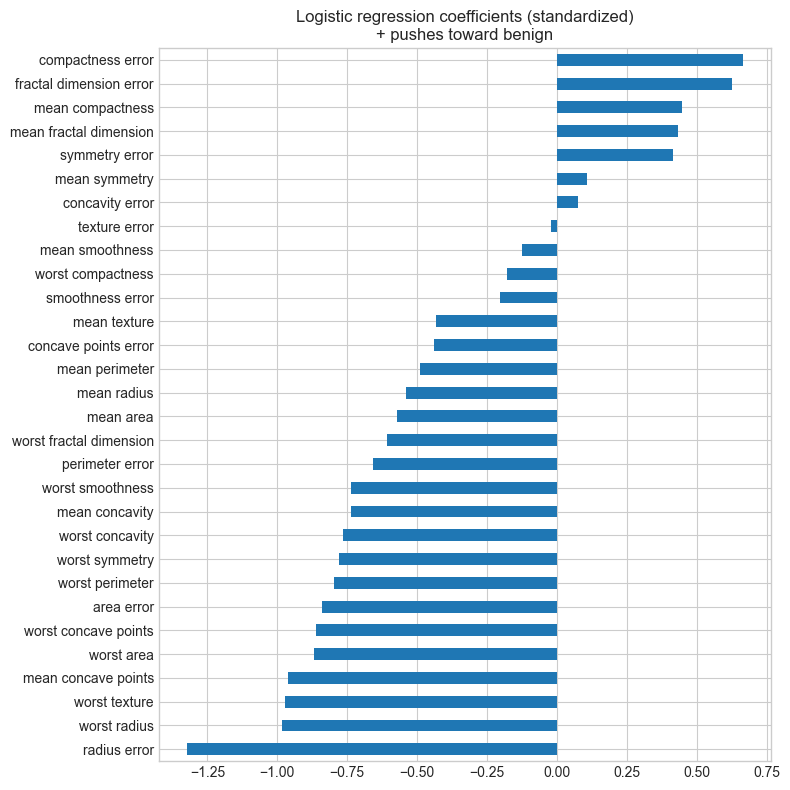

In [4]:
from sklearn.linear_model import LogisticRegression

logreg = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
logreg.fit(X_train, y_train)

coefs = pd.Series(logreg[-1].coef_[0], index=X.columns).sort_values()
coefs.plot.barh(figsize=(8, 8), title="Logistic regression coefficients (standardized)\n+ pushes toward benign");

Each coefficient is the change in **log-odds** per standard deviation of its feature. `np.exp(coef)` turns it into an odds ratio.
`C` is the inverse regularization strength. Smaller `C` means a stronger penalty. Set `penalty="l1", solver="liblinear"`
to get Lasso-style feature selection.

## 4. Evaluate: more than accuracy

Accuracy: 0.982   ROC AUC: 0.996

              precision    recall  f1-score   support

   malignant       1.00      0.95      0.98        42
      benign       0.97      1.00      0.99        72

    accuracy                           0.98       114
   macro avg       0.99      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



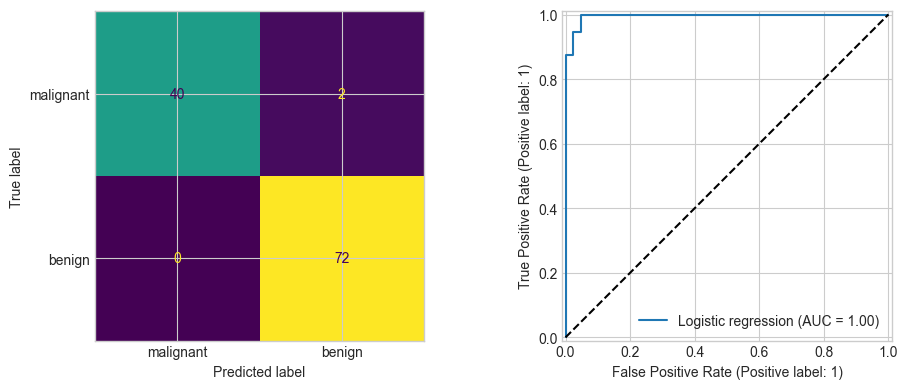

In [5]:
y_pred = logreg.predict(X_test)
y_prob = logreg.predict_proba(X_test)[:, 1]

print(f"Accuracy: {accuracy_score(y_test, y_pred):.3f}   ROC AUC: {roc_auc_score(y_test, y_prob):.3f}\n")
print(classification_report(y_test, y_pred, target_names=data.target_names))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=data.target_names, ax=ax1, colorbar=False)
RocCurveDisplay.from_predictions(y_test, y_prob, ax=ax2, name="Logistic regression")
ax2.plot([0, 1], [0, 1], "k--");

- **Precision**: of the cases predicted positive, the fraction that really are. **Recall**: of the real positives, the fraction found.
- **ROC AUC**: the probability that a random positive is ranked above a random negative. It doesn't depend on the threshold.
- The default threshold is 0.5. When a missed case costs more than a false alarm (as with a malignant tumour), lower the threshold
  on `predict_proba` instead of retraining.

## 5. Non-linear models
All six models go through the same 5-fold CV. Put the scale-sensitive ones in a pipeline with `StandardScaler`.

In [6]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.svm import SVC

models = {
    "Logistic regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "k-NN":                make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
    "Decision tree":       DecisionTreeClassifier(max_depth=4, random_state=0),
    "Random forest":       RandomForestClassifier(n_estimators=300, random_state=0),
    "Gradient boosting":   HistGradientBoostingClassifier(random_state=0),
    "SVM (RBF)":           make_pipeline(StandardScaler(), SVC(kernel="rbf", probability=True, random_state=0)),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
results = pd.DataFrame({
    name: {
        "CV accuracy": cross_val_score(m, X_train, y_train, cv=cv, scoring="accuracy").mean(),
        "CV ROC AUC": cross_val_score(m, X_train, y_train, cv=cv, scoring="roc_auc").mean(),
    }
    for name, m in models.items()
}).T.sort_values("CV ROC AUC", ascending=False)
results

,CV accuracy,CV ROC AUC
SVM (RBF),0.980220,0.996594
Logistic regression,0.978022,0.994737
Random forest,0.960440,0.993602
Gradient boosting,0.962637,0.990093
k-NN,0.964835,0.987926
Decision tree,0.927473,0.936275


### Seeing the difference: decision boundaries on 2 features
Linear vs. neighbourhoods vs. axis-aligned splits vs. smooth curves.

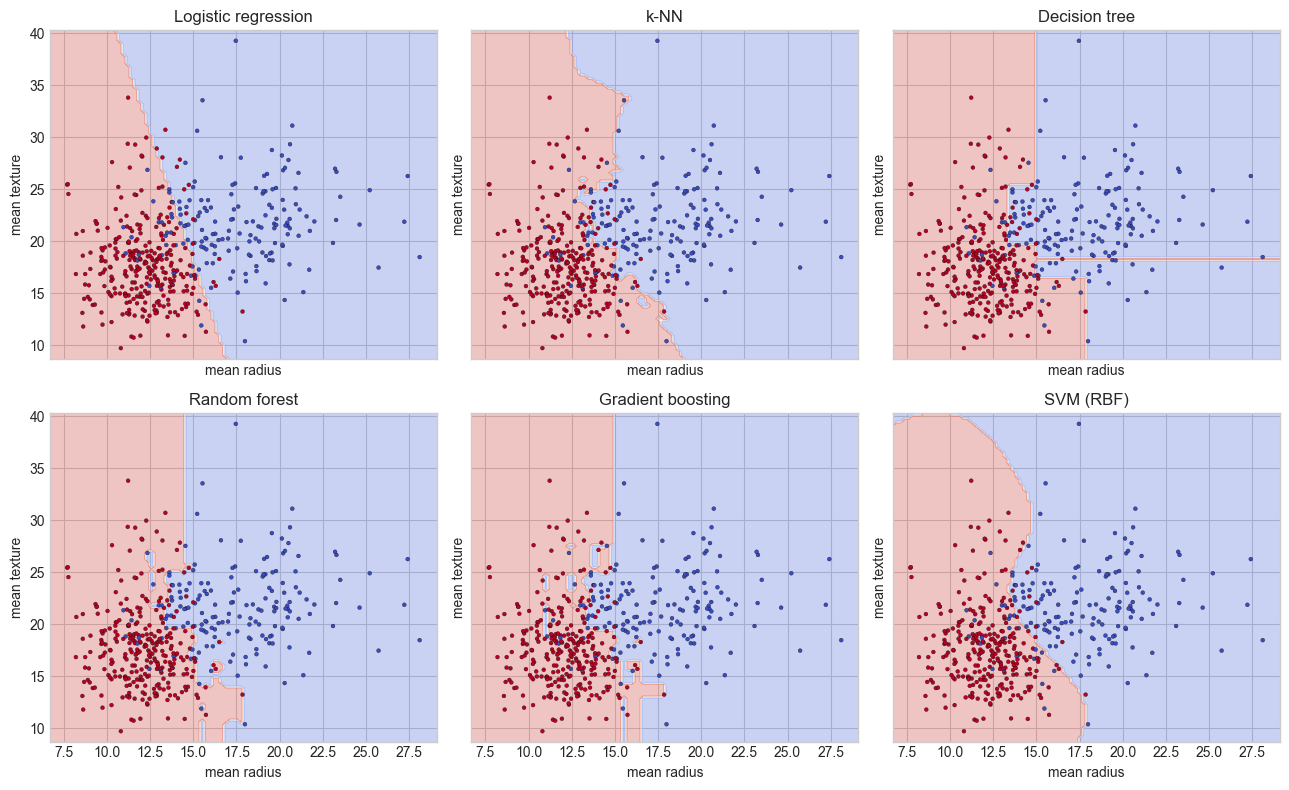

In [7]:
from sklearn.inspection import DecisionBoundaryDisplay

two = ["mean radius", "mean texture"]
fig, axs = plt.subplots(2, 3, figsize=(13, 8), sharex=True, sharey=True)
for ax, (name, m) in zip(axs.ravel(), models.items()):
    m.fit(X_train[two], y_train)
    DecisionBoundaryDisplay.from_estimator(m, X_train[two], response_method="predict", alpha=0.3, cmap="coolwarm", ax=ax)
    ax.scatter(X_train[two[0]], X_train[two[1]], c=y_train, cmap="coolwarm", s=8, edgecolor="k", linewidth=0.2)
    ax.set_title(name)

## 6. Tune the best model, then evaluate once on the test set
Each model has one or two hyperparameters that matter most:

| Model | Tune first |
|---|---|
| Logistic regression | `C` |
| k-NN | `n_neighbors` |
| Decision tree | `max_depth`, `min_samples_leaf` |
| Random forest | `n_estimators` (more is safe), `max_features`, `min_samples_leaf` |
| Gradient boosting | `learning_rate`, `max_iter`, `max_depth` |
| SVM (RBF) | `C`, `gamma` |

In [8]:
search = GridSearchCV(
    RandomForestClassifier(n_estimators=300, random_state=0),
    param_grid={"max_features": ["sqrt", 0.3, 0.5], "min_samples_leaf": [1, 3, 5]},
    cv=cv, scoring="roc_auc",
).fit(X_train, y_train)
print("Best params:", search.best_params_, f" CV ROC AUC: {search.best_score_:.4f}")

Best params: {'max_features': 'sqrt', 'min_samples_leaf': 1}  CV ROC AUC: 0.9936


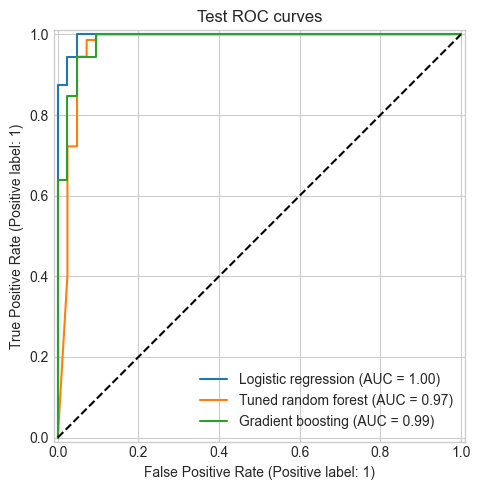

In [9]:
fig, ax = plt.subplots(figsize=(6, 5))
for name, m in {"Logistic regression": models["Logistic regression"], "Tuned random forest": search.best_estimator_,
                "Gradient boosting": models["Gradient boosting"]}.items():
    m.fit(X_train, y_train)
    RocCurveDisplay.from_estimator(m, X_test, y_test, ax=ax, name=name)
ax.plot([0, 1], [0, 1], "k--")
ax.set_title("Test ROC curves");

### Which features does the forest rely on?

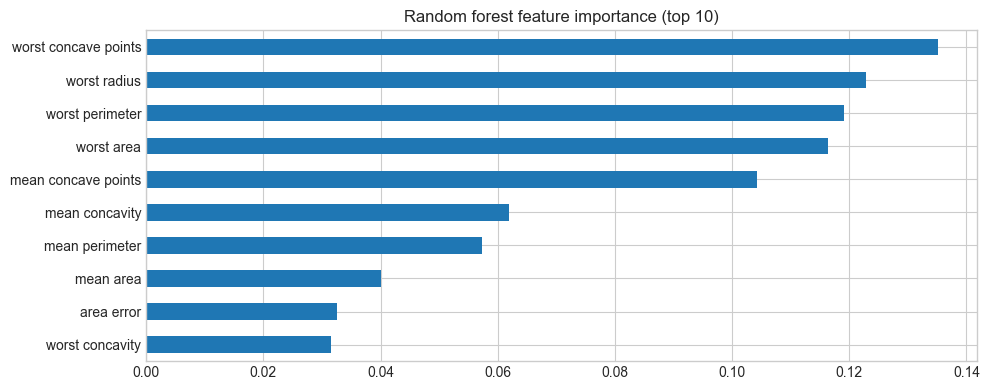

In [10]:
importances = pd.Series(search.best_estimator_.feature_importances_, index=X.columns).sort_values()
importances.tail(10).plot.barh(title="Random forest feature importance (top 10)");

**Takeaways**
- Start with logistic regression. It's fast and interpretable, and it's often hard to beat on clean, roughly linear data like this.
- **Random forest** and **gradient boosting** are the standard non-linear choices for tabular data. They need no scaling and little tuning.
- Scale the features for logistic regression, k-NN and SVM. Tree models don't care about scale.
- Choose the metric for the problem (AUC, recall, F1), compare with stratified CV, and touch the test set once.